In [3]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# Load original dataset
df = pd.read_csv(
    "../Data/CosciaRios2012_DataBase.csv"
)

# Load geographical boundaries
gdf = gpd.read_file(
    "../Data/Boundaries/Municipios_2010_5.shp"
)

print(df.shape)
print(gdf.shape)

print(df.columns.tolist())
print(gdf.columns.tolist())

(51596, 13)
(2456, 5)
['Code', 'State', 'Year', 'Beltran_Leyva', 'Beltran_Leyva_Family', 'Familia', 'Golfo', 'Juarez', 'Sinaloa', 'Sinaloa_Family', 'Tijuana', 'Zetas', 'Otros']
['CVE_ENT', 'CVE_MUN', 'NOM_MUN', 'OID', 'geometry']


In [4]:
df["Code"] = df["Code"].astype(str).str.zfill(5)

gdf["Code"] = (
    gdf["CVE_ENT"].astype(str).str.zfill(2)
    + gdf["CVE_MUN"].astype(str).str.zfill(3)
)

In [5]:
gdf["Code"] = gdf["CVE_ENT"] + gdf["CVE_MUN"]

print("Boundary codes:", gdf["Code"].nunique())
print("CSV codes:", df["Code"].nunique())

missing_from_map = set(df["Code"].astype(str)) - set(gdf["Code"])
missing_from_csv = set(gdf["Code"]) - set(df["Code"].astype(str))

print("CSV municipalities without boundary:", missing_from_map)
print("Boundaries without CSV municipality:", missing_from_csv)

Boundary codes: 2456
CSV codes: 2457
CSV municipalities without boundary: {'23010'}
Boundaries without CSV municipality: set()


In [6]:
merged = gdf.merge(
    df,
    on="Code",
    how="left"
)

print("Municipal polygons:", len(merged))
print("Unmatched CSV municipality:", "23010")

Municipal polygons: 51575
Unmatched CSV municipality: 23010


In [7]:
df_2010 = df[df["Year"] == 2010]

map_2010 = gdf.merge(
    df_2010,
    on="Code",
    how="left"
)

print("Rows:", len(map_2010))
print("Unique municipalities:", map_2010["Code"].nunique())

Rows: 2456
Unique municipalities: 2456


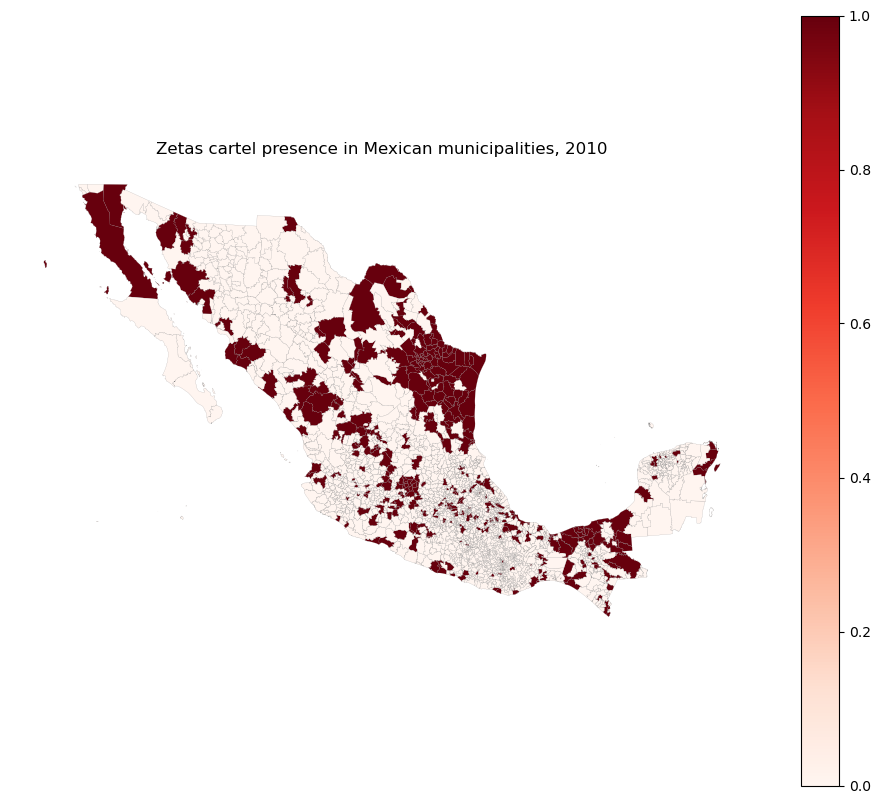

In [23]:
cartel = "Zetas"

map_2010[cartel] = map_2010[cartel].fillna(0)

fig, ax = plt.subplots(figsize=(12, 10))

map_2010.plot(
    column=cartel,
    cmap="Reds",
    legend=True,
    linewidth=0.1,
    edgecolor="gray",
    ax=ax
)

ax.set_title(f"{cartel} cartel presence in Mexican municipalities, 2010")
ax.axis("off")

plt.show()

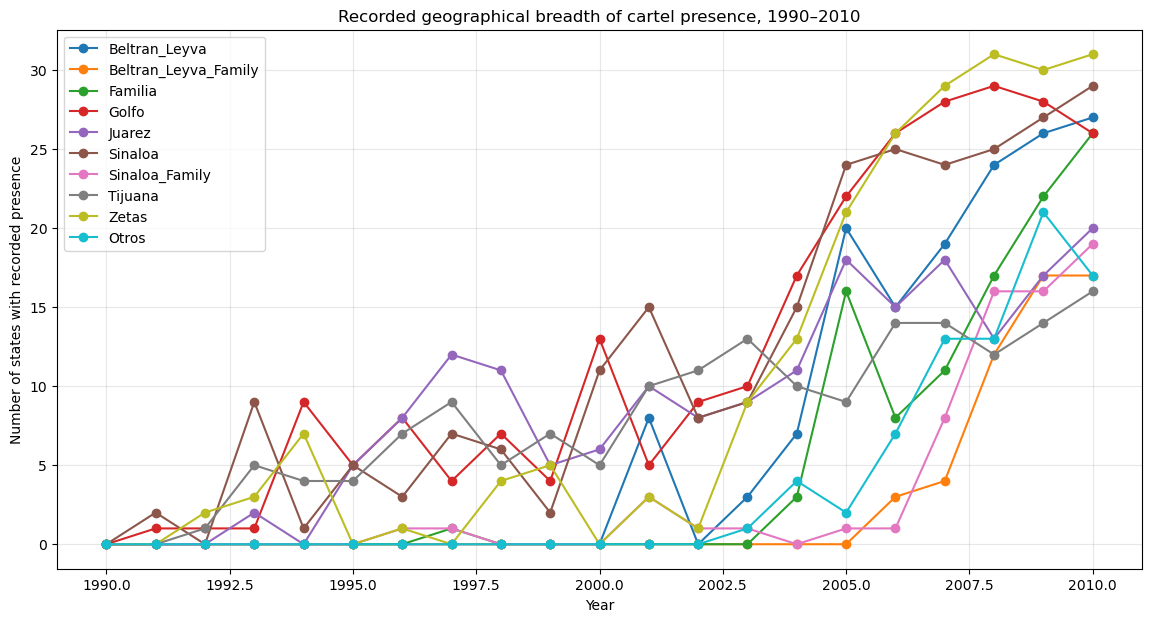

In [19]:
state_year = (
    df.groupby(["State", "Year"])[cartel_columns]
      .sum()
      .reset_index()
)

state_presence = (
    state_year.groupby("Year")[cartel_columns]
    .apply(lambda x: (x > 0).sum())
    .reset_index()
)

state_presence.set_index("Year")[cartel_columns].plot(
    figsize=(14, 7),
    marker="o"
)

plt.ylabel("Number of states with recorded presence")
plt.xlabel("Year")
plt.title("Recorded geographical breadth of cartel presence, 1990–2010")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
municipality_presence = (
    df.groupby("Year")[cartel_columns]
      .sum()
      .reset_index()
)

municipality_presence

In [ ]:
municipality_presence.set_index("Year")[cartel_columns].plot(
    figsize=(14, 7),
    marker="o"
)

plt.title("Recorded municipal presence of cartel indicators, 1990–2010")
plt.xlabel("Year")
plt.ylabel("Number of municipalities with recorded presence")
plt.grid(alpha=0.3)
plt.legend(title="Cartel indicator", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

In [ ]:
annual_change = municipality_presence.set_index("Year")[cartel_columns].diff()

annual_change

In [ ]:
annual_change.max().sort_values(ascending=False)

In [10]:
import libpysal
from libpysal.weights import Queen

#Queen-contiguity neighbours
w = Queen.from_dataframe(gdf, ids="Code")

#Number of neighbouring municipalities for each municipality
gdf["n_neighbours"] = gdf["Code"].map(w.cardinalities)

print(gdf[["Code", "NOM_MUN", "n_neighbours"]].head())

    Code                 NOM_MUN  n_neighbours
0  09012                 Tlalpan             9
1  09013              Xochimilco             5
2  09008  La Magdalena Contreras             3
3  09002            Azcapotzalco             5
4  09014           Benito Juárez             6


In [11]:
# Check the neighbours of one municipality
w.neighbors["09012"]

['09003',
 '15062',
 '15043',
 '09013',
 '15101',
 '17009',
 '09009',
 '09010',
 '09008']

In [21]:
# Load municipality polygons
edges = []

for i, row1 in gdf.iterrows():
    neighbors = gdf[gdf.geometry.touches(row1.geometry)]

    for _, row2 in neighbors.iterrows():
        if row1["Code"] < row2["Code"]:
            edges.append(
                (
                    row1["Code"],
                    row2["Code"]
                )
            )

edge_df = pd.DataFrame(edges, columns=["source", "target"])
edge_df.to_csv("mexico_municipality_network.csv", index=False)

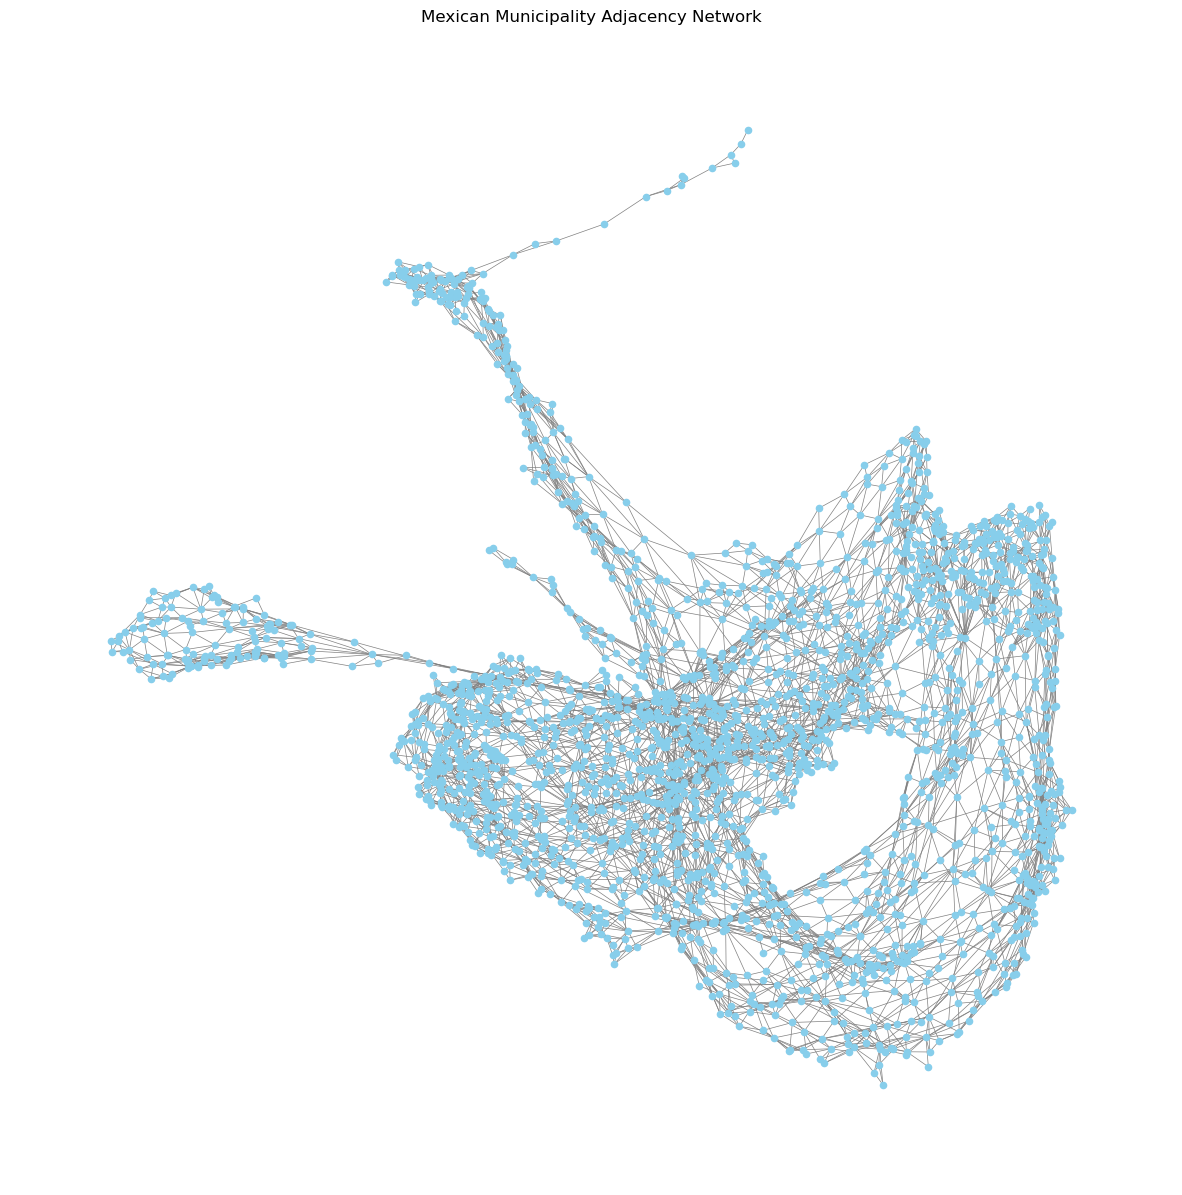

In [22]:
import networkx as nx

# Create network
G = nx.from_pandas_edgelist(
    edge_df,
    source="source",
    target="target"
)

# Plot
plt.figure(figsize=(15, 15))

pos = nx.spring_layout(G, seed=42)

nx.draw_networkx(
    G,
    pos,
    node_size=20,
    node_color="skyblue",
    edge_color="gray",
    width=0.5,
    with_labels=False
)

plt.title("Mexican Municipality Adjacency Network")
plt.axis("off")
plt.show()

----------------------------------------------------------------------------------------------

----------------------------------------------------------------------------------------------

In [13]:
# Inspect data types
print(df.dtypes)

# Number of unique states
print("States:", df["State"].nunique())

# Number of unique years
print("Years:", df["Year"].nunique())

# Missing values
print(df.isnull().sum())

Code                    object
State                    int64
Year                     int64
Beltran_Leyva            int64
Beltran_Leyva_Family     int64
Familia                  int64
Golfo                    int64
Juarez                   int64
Sinaloa                  int64
Sinaloa_Family           int64
Tijuana                  int64
Zetas                    int64
Otros                    int64
dtype: object
States: 32
Years: 21
Code                    0
State                   0
Year                    0
Beltran_Leyva           0
Beltran_Leyva_Family    0
Familia                 0
Golfo                   0
Juarez                  0
Sinaloa                 0
Sinaloa_Family          0
Tijuana                 0
Zetas                   0
Otros                   0
dtype: int64


In [14]:
# Check duplicate municipality-year combinations
duplicates = df.duplicated(
    subset=["Code", "Year"]
).sum()

print("Duplicate observations:", duplicates)

# Check year range
print("First year:", df["Year"].min())
print("Last year:", df["Year"].max())

# Check cartel indicators
cartel_columns = [
    "Beltran_Leyva",
    "Beltran_Leyva_Family",
    "Familia",
    "Golfo",
    "Juarez",
    "Sinaloa",
    "Sinaloa_Family",
    "Tijuana",
    "Zetas",
    "Otros"
]

for col in cartel_columns:
    print(col, df[col].unique())

Duplicate observations: 0
First year: 1990
Last year: 2010
Beltran_Leyva [0 1]
Beltran_Leyva_Family [0 1]
Familia [0 1]
Golfo [0 1]
Juarez [0 1]
Sinaloa [0 1]
Sinaloa_Family [0 1]
Tijuana [0 1]
Zetas [0 1]
Otros [0 1]


In [15]:
state_year = (
    df.groupby(["State", "Year"])[cartel_columns]
      .sum()
      .reset_index()
)

print(state_year.head())
print(state_year.shape)

   State  Year  Beltran_Leyva  Beltran_Leyva_Family  Familia  Golfo  Juarez  \
0      1  1990              0                     0        0      0       0   
1      1  1991              0                     0        0      0       0   
2      1  1992              0                     0        0      0       0   
3      1  1993              0                     0        0      0       0   
4      1  1994              0                     0        0      0       0   

   Sinaloa  Sinaloa_Family  Tijuana  Zetas  Otros  
0        0               0        0      0      0  
1        0               0        0      0      0  
2        0               0        0      0      0  
3        0               0        0      0      0  
4        0               0        0      0      0  
(672, 12)


In [16]:
national_year = (
    state_year
    .groupby("Year")[cartel_columns]
    .sum()
    .reset_index()
)

print(national_year.head())

   Year  Beltran_Leyva  Beltran_Leyva_Family  Familia  Golfo  Juarez  Sinaloa  \
0  1990              0                     0        0      0       0        0   
1  1991              0                     0        0      3       0        3   
2  1992              0                     0        0      1       0        0   
3  1993              0                     0        0      1       2       12   
4  1994              0                     0        0     13       0        2   

   Sinaloa_Family  Tijuana  Zetas  Otros  
0               0        0      0      0  
1               0        0      0      0  
2               0        3      2      0  
3               0        6      3      0  
4               0        6     10      0  


ACTUAL RESEARCH

In [17]:
state_presence = (
    state_year
    .groupby("Year")[cartel_columns]
    .apply(lambda x: (x > 0).sum())
    .reset_index()
)

print(state_presence.head())

   Year  Beltran_Leyva  Beltran_Leyva_Family  Familia  Golfo  Juarez  Sinaloa  \
0  1990              0                     0        0      0       0        0   
1  1991              0                     0        0      1       0        2   
2  1992              0                     0        0      1       0        0   
3  1993              0                     0        0      1       2        9   
4  1994              0                     0        0      9       0        1   

   Sinaloa_Family  Tijuana  Zetas  Otros  
0               0        0      0      0  
1               0        0      0      0  
2               0        1      2      0  
3               0        5      3      0  
4               0        4      7      0  


In [18]:
# Compare geographical breadth in 1990 and 2010

comparison = state_presence.set_index("Year").loc[
    [1990, 2010], cartel_columns
].T

comparison.columns = ["1990", "2010"]

comparison["Change"] = (
    comparison["2010"] - comparison["1990"]
)

comparison = comparison.sort_values(
    "Change", ascending=False
)

print(comparison)

                      1990  2010  Change
Zetas                    0    31      31
Sinaloa                  0    29      29
Beltran_Leyva            0    27      27
Familia                  0    26      26
Golfo                    0    26      26
Juarez                   0    20      20
Sinaloa_Family           0    19      19
Beltran_Leyva_Family     0    17      17
Otros                    0    17      17
Tijuana                  0    16      16


In [ ]:
for cartel in cartel_columns:
    positive_years = state_presence.loc[
        state_presence[cartel] > 0, "Year"
    ]

    if len(positive_years) > 0:
        first_year = positive_years.min()
        last_year = positive_years.max()

        print(
            cartel,
            "First recorded year:", first_year,
            "Last recorded year:", last_year
        )
    else:
        print(cartel, "No recorded presence")